# **Music Clustering Analysis Using Spotify Audio FeaturesKnowledge Base Enrichment & Dimensionality Reduction**


# Spotify Music Clustering Analysis

## Unsupervised Learning on Spotify Audio Features

This project explores the structure of Spotify music data by applying unsupervised learning techniques to discover hidden patterns among songs. The analysis combines song metadata and audio features to identify groups of tracks with similar musical characteristics.

The notebook covers data preprocessing, exploratory data analysis, clustering using K-Means and DBSCAN, dimensionality reduction techniques (PCA, ISOMAP, and t-SNE), and cluster evaluation using multiple validation metrics.



## Introduction

Music streaming platforms such as Spotify generate large amounts of data describing songs and their acoustic properties. Each track can be characterized by multiple audio features such as danceability, energy, loudness, acousticness, tempo, and valence. These features provide a numerical representation of musical characteristics that can be analyzed using machine learning techniques.

The objective of this project is to explore the structure of Spotify song data and discover natural groupings of songs based on their audio features. Since the dataset does not contain predefined labels for song groups, unsupervised learning methods are used to identify hidden patterns in the data.

To achieve this goal, two Spotify datasets containing song metadata and audio features are merged and analyzed. The workflow includes data cleaning, exploratory data analysis (EDA), clustering using K-Means and DBSCAN algorithms, and visualization of the data structure using dimensionality reduction techniques such as PCA, ISOMAP, and t-SNE.

Finally, clustering performance is evaluated using internal validation metrics including the Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index to assess the quality and stability of the discovered clusters.

1. Introduction
2. Dataset Description
3. Data Preprocessing
4. Exploratory Data Analysis
5. Feature Correlation Analysis
6. Clustering with K-Means
7. DBSCAN Clustering
8. Dimensionality Reduction (PCA, ISOMAP, t-SNE)
9. Cluster Evaluation
10. Comparison of Feature Spaces
11. Conclusion

## import necessary libraries

In [ ]:
# Basic Imports
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn import set_config

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.19.0
GPU available: []


## dataset description

In [ ]:
# Load main_dataset data
from google.colab import files
uploaded = files.upload()


Saving main_dataset.csv to main_dataset.csv


In [ ]:

data_1 =pd.read_csv('main_dataset.csv')
data_1.head(5)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [ ]:
# Load Enriched_dataset data
from google.colab import files
uploaded = files.upload()

Saving Enriched_Dataset.csv to Enriched_Dataset.csv


In [ ]:
# Load data
data_2 =pd.read_csv('Enriched_Dataset.csv')
data_2.head(5)

,Unnamed: 0.1,Unnamed: 0,id,name,artist,genres,danceability,energy,key,loudness,...,valence,tempo,type,uri,track_href,analysis_url,duration_ms,time_signature,error,popularity
0,0,0.0,5tq3Ygbw8ReO3pkehrmdFH,Cumbias del pasado,Victor Bernal,['pop'],0.520,0.989,9.0,2.121,...,0.684,98.950,audio_features,spotify:track:5tq3Ygbw8ReO3pkehrmdFH,https://api.spotify.com/v1/tracks/5tq3Ygbw8ReO...,https://api.spotify.com/v1/audio-analysis/5tq3...,347128.0,4.0,NaN,NaN
1,1,1.0,3XGY5swlPLOmdSuMeuGxol,Babo Barish Kar De Paiso Ki,Raju Punjabi,['pop'],0.850,0.807,11.0,-6.950,...,0.590,117.996,audio_features,spotify:track:3XGY5swlPLOmdSuMeuGxol,https://api.spotify.com/v1/tracks/3XGY5swlPLOm...,https://api.spotify.com/v1/audio-analysis/3XGY...,272605.0,4.0,NaN,NaN
2,2,2.0,3q2cfRnoHTAhiWJgIxQvqA,Asharuwa,Mynmaster productions,['pop'],0.737,0.729,2.0,-9.938,...,0.940,105.092,audio_features,spotify:track:3q2cfRnoHTAhiWJgIxQvqA,https://api.spotify.com/v1/tracks/3q2cfRnoHTAh...,https://api.spotify.com/v1/audio-analysis/3q2c...,271621.0,4.0,NaN,NaN
3,3,3.0,3q2cfRnoHTAhiWJgIxQvqA,Asharuwa,Mynmaster productions,['pop'],0.737,0.729,2.0,-9.938,...,0.940,105.092,audio_features,spotify:track:3q2cfRnoHTAhiWJgIxQvqA,https://api.spotify.com/v1/tracks/3q2cfRnoHTAh...,https://api.spotify.com/v1/audio-analysis/3q2c...,271621.0,4.0,NaN,NaN
4,4,4.0,0O9RWQNpRlEcAaf3IEegbY,Limeryki dla odmladzajacych sie,Halina Kunicka,['pop'],0.426,0.494,11.0,-12.883,...,0.867,115.615,audio_features,spotify:track:0O9RWQNpRlEcAaf3IEegbY,https://api.spotify.com/v1/tracks/0O9RWQNpRlEc...,https://api.spotify.com/v1/audio-analysis/0O9R...,161991.0,5.0,NaN,NaN


In [ ]:
data_1.shape # check the shape of dataset 1

(114000, 21)

In [ ]:
# data type
data_1.dtypes

,0
Unnamed: 0,int64
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64
energy,float64


In [ ]:
data_1.isna().sum() # check nan value

,0
Unnamed: 0,0
track_id,0
artists,1
album_name,1
track_name,1
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0


In [ ]:
df1_clean = data_1.dropna() # drop null value

In [ ]:
df1_clean.duplicated().sum() # there is no duplicate row the dataset rows are completely identical

np.int64(0)

In [ ]:
df1_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 113999 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        113999 non-null  int64  
 1   track_id          113999 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        113999 non-null  int64  
 6   duration_ms       113999 non-null  int64  
 7   explicit          113999 non-null  bool   
 8   danceability      113999 non-null  float64
 9   energy            113999 non-null  float64
 10  key               113999 non-null  int64  
 11  loudness          113999 non-null  float64
 12  mode              113999 non-null  int64  
 13  speechiness       113999 non-null  float64
 14  acousticness      113999 non-null  float64
 15  instrumentalness  113999 non-null  float64
 16  liveness          113999 

## keep metadata only for dataset 1

The initial dataset contained both metadata and acoustic signal features. To ensure meaningful knowledge base enrichment, only descriptive attributes (artist, album, genre, popularity) were retained, while technical audio attributes were sourced from the secondary dataset to avoid redundancy and preserve enrichment integrity.

In [ ]:
df1_clean = df1_clean[[
    'track_id',
    'artists',
    'album_name',
    'track_name',
    'popularity',
    'explicit',
    'track_genre'
]]

In [ ]:
df1_clean.dtypes # check the types of each column

,0
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
explicit,bool
track_genre,object


## Now work on Dataset 2

In [ ]:
# data_2.info()

## Only quantitative acoustic signal features were retained, as they provide meaningful dimensions for unsupervised learning and manifold learning techniques. we remove Text, links, duplicates, and useless metadata.

In [ ]:
# df2_clean = data_2[[
#     'id',
#     'danceability',
#     'energy',
#     'key',
#     'loudness',
#     'mode',
#     'speechiness',
#     'acousticness',
#     'instrumentalness',
#     'liveness',
#     'valence',
#     'tempo',
#     'duration_ms',
#     'time_signature'
# ]
# ]

In [ ]:
# df2_clean.isna().sum()

In [ ]:
#df2_clean.info()

## Merge Both Datasets (Enrichment Step)

To improve dataset integration, textual normalization was applied to the track_name and artist column . The preprocessing procedure converted text to lowercase, removed version descriptors (e.g., remastered or remix information), eliminated featured artist annotations, and removed special characters. This cleaning process reduced inconsistencies between datasets and allowed the creation of standardized fields (track_name_clean and artists_clean) used for merging the two datasets.

In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"\(.*?\)", "", text)  # remove text inside ()
    text = re.sub(r"feat\..*", "", text)  # remove feat.
    text = re.sub(r"-.*", "", text)  # remove after "-"
    text = re.sub(r"[^\w\s]", "", text)  # remove special characters
    return text.strip()

df1_clean['track_name_clean'] = df1_clean['track_name'].apply(clean_text)
df1_clean['artists_clean'] = df1_clean['artists'].apply(clean_text)

data_2['track_name_clean'] = data_2['name'].apply(clean_text)
data_2['artists_clean'] = data_2['artist'].apply(clean_text)



In [ ]:
df_merged = pd.merge(
    df1_clean,
    data_2,
    on=['track_name_clean', 'artists_clean'],
    how='inner'
)

In [ ]:
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          549 non-null    object 
 1   artists           549 non-null    object 
 2   album_name        549 non-null    object 
 3   track_name        549 non-null    object 
 4   popularity_x      549 non-null    int64  
 5   explicit          549 non-null    bool   
 6   track_genre       549 non-null    object 
 7   track_name_clean  549 non-null    object 
 8   artists_clean     549 non-null    object 
 9   Unnamed: 0.1      549 non-null    int64  
 10  Unnamed: 0        204 non-null    float64
 11  id                549 non-null    object 
 12  name              549 non-null    object 
 13  artist            549 non-null    object 
 14  genres            549 non-null    object 
 15  danceability      549 non-null    float64
 16  energy            549 non-null    float64
 1

In [ ]:
#  Keep popularity from dataset 1 (popularity_x) and rename it we will remove popularity_y from dataset 2
df_clean = df_merged.rename(columns={"popularity_x": "popularity"})

#  Select useful columns only
keep_cols = [
    "track_id", "artists", "album_name", "track_name",
    "popularity", "explicit", "track_genre",
    "danceability", "energy", "key", "loudness", "mode",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo", "duration_ms", "time_signature"
]
df_clean = df_clean[keep_cols]

#  Fix dtype
df_clean["explicit"] = df_clean["explicit"].astype(int)

# Remove duplicates (one row per track)
df_final = df_clean.drop_duplicates(subset=["track_id"])

print(df_final.shape)
df_final.head()

(228, 20)


,track_id,artists,album_name,track_name,popularity,explicit,track_genre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
0,0S51NLrTscfLemwPv2rjNv,No Doubt,Hits Pop Rock 90's,Just A Girl,1,0,alt-rock,0.635,0.937,2.0,-2.860,1.0,0.0452,0.0735,0.000069,0.1340,0.780,108.003,205947.0,4.0
2,19DhbcqPx96nCoPvm6ViUV,Simply Red,Session Acoustique,Holding Back the Years,0,0,british,0.710,0.514,9.0,-8.885,0.0,0.0278,0.5800,0.000159,0.0953,0.517,86.020,269840.0,4.0
3,1yg7fwwYmx9DQ2TdXUmfpJ,Simply Red,Picture Book (Expanded Version),Holding Back the Years - 2008 Remaster,68,0,british,0.710,0.514,9.0,-8.885,0.0,0.0278,0.5800,0.000159,0.0953,0.517,86.020,269840.0,4.0
4,7zWPS8cNSxWgGz6U00OIyT,Dolly Parton,Country Holiday,"Mary, Did You Know?",0,0,country,0.355,0.382,10.0,-9.257,0.0,0.0378,0.7840,0.000000,0.1230,0.261,95.994,266506.0,4.0
5,6ocbgoVGwYJhOv1GgI9NsF,Ariana Grande,"thank u, next",7 rings,84,1,dance,0.725,0.321,1.0,-10.744,0.0,0.3230,0.5780,0.000000,0.0884,0.319,70.142,178640.0,4.0


# EDA

In [ ]:
print("Shape:", df_final.shape)
df_final.info()
df_final.describe()

Shape: (228, 20)
<class 'pandas.core.frame.DataFrame'>
Index: 228 entries, 0 to 547
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          228 non-null    object 
 1   artists           228 non-null    object 
 2   album_name        228 non-null    object 
 3   track_name        228 non-null    object 
 4   popularity        228 non-null    int64  
 5   explicit          228 non-null    int64  
 6   track_genre       228 non-null    object 
 7   danceability      228 non-null    float64
 8   energy            228 non-null    float64
 9   key               228 non-null    float64
 10  loudness          228 non-null    float64
 11  mode              228 non-null    float64
 12  speechiness       228 non-null    float64
 13  acousticness      228 non-null    float64
 14  instrumentalness  228 non-null    float64
 15  liveness          228 non-null    float64
 16  valence           228 non-null  

,popularity,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
count,228.000000,228.000000,228.000000,228.000000,228.000000,228.000000,228.000000,228.000000,228.000000,228.000000,228.000000,228.000000,228.000000,2.280000e+02,228.000000
mean,39.614035,0.096491,0.648018,0.636575,4.969298,-7.817434,0.627193,0.125192,0.261398,0.063917,0.203009,0.510211,123.176408,2.839424e+05,3.741228
std,32.590642,0.295913,0.145772,0.172318,3.844319,3.740624,0.484615,0.138095,0.255684,0.197230,0.172447,0.234936,27.464716,3.158938e+05,0.773266
min,0.000000,0.000000,0.170000,0.224000,0.000000,-21.837000,0.000000,0.024400,0.000151,0.000000,0.038300,0.056400,70.142000,3.850000e+04,1.000000
25%,1.000000,0.000000,0.538000,0.512000,1.000000,-9.407500,0.000000,0.037750,0.054975,0.000000,0.095300,0.305500,100.115500,1.879870e+05,4.000000
50%,40.000000,0.000000,0.697000,0.652500,5.000000,-6.979500,1.000000,0.059000,0.211000,0.000006,0.126000,0.547500,123.028000,2.080600e+05,4.000000
75%,73.000000,0.000000,0.752000,0.803000,8.000000,-5.178250,1.000000,0.130000,0.382000,0.001121,0.266250,0.727250,137.493000,2.434635e+05,4.000000
max,89.000000,1.000000,0.888000,0.960000,11.000000,-2.080000,1.000000,0.483000,0.962000,0.971000,0.942000,0.968000,184.980000,2.889646e+06,5.000000


The dataset contains 228 enriched tracks described by 15 numerical acoustic features. The descriptive statistics reveal substantial variability in energy, danceability, tempo, and acousticness, indicating a heterogeneous musical space suitable for unsupervised learning and manifold analysis.

The descriptive statistics indicate that the average track duration is approximately 283,942 milliseconds (around 4.7 minutes), which is consistent with typical commercial music lengths. However, the maximum duration reaches 2,889,646 milliseconds (approximately 48 minutes), which is significantly higher than the dataset mean. This suggests the presence of potential outliers, possibly representing extended mixes, live recordings, special editions, or data inconsistencies. Such extreme values may influence clustering performance and distance-based methods, and therefore should be carefully examined before applying dimensionality reduction and unsupervised learning algorithms.

## Popularity distribution

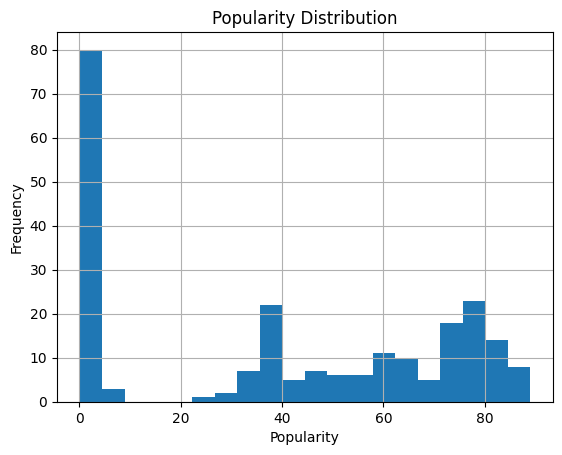

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
df_final["popularity"].hist(bins=20)
plt.title("Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Frequency")
plt.show()

popularity is:

Not normally distributed
,Likely right-skewed
,Possibly multi-modal (more than one peak)

This is actually GOOD for clustering because:

✔ There is variation
✔ There are distinguishable groups
✔ Popularity may influence cluster formation

## Genre

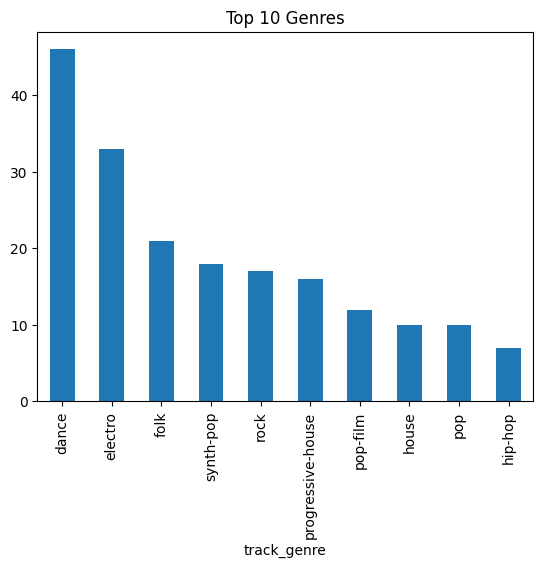

In [ ]:
df_final["track_genre"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Genres")
plt.show()

✔ Multi-genre
✔ Moderately imbalanced
✔ Not single-genre biased
✔ Diverse in musical styles

This is good for clustering because:

Different genres may form natural clusters

Audio features will vary between genres

Dimensionality reduction may reveal genre-based grouping

## Correlation Matrix

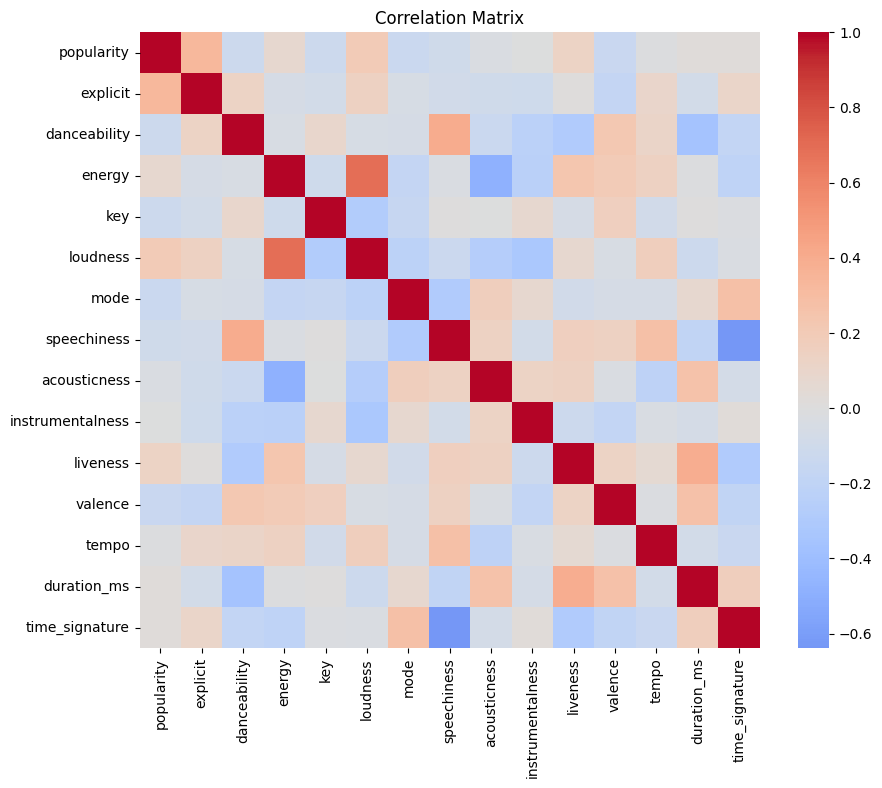

In [ ]:
import seaborn as sns

num_cols = df_final.select_dtypes(include=["int64","float64"]).columns

plt.figure(figsize=(10,8))
sns.heatmap(df_final[num_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

The correlation matrix reveals several meaningful relationships among acoustic features. A strong positive correlation is observed between energy and loudness, indicating that more energetic tracks tend to exhibit higher amplitude levels. Additionally, a strong negative correlation exists between energy and acousticness, suggesting that acoustic tracks are generally less energetic. Danceability and valence show moderate positive correlation, implying that rhythmically engaging songs often convey positive emotional characteristics. In contrast, popularity exhibits weak correlations with most acoustic features, indicating that commercial success is not solely driven by intrinsic audio properties. These inter-feature relationships justify the application of dimensionality reduction techniques to identify latent musical structures.

## Features distribution

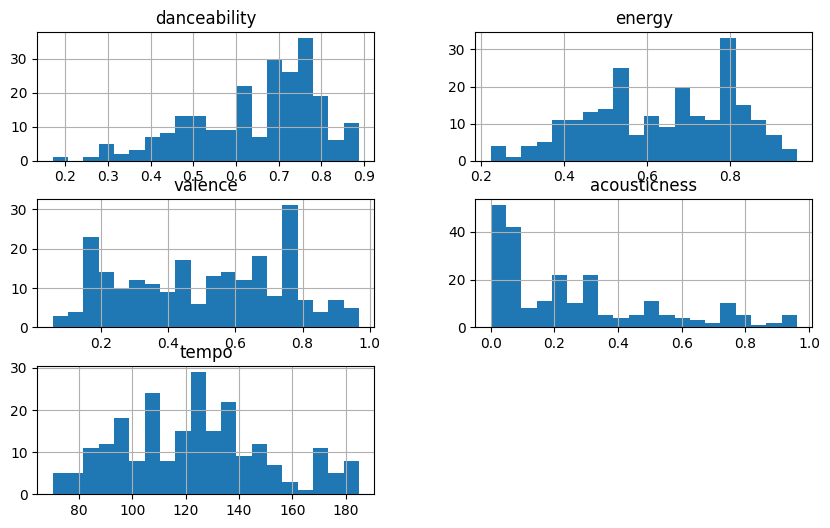

In [ ]:
features_to_plot = ["danceability","energy","valence","acousticness","tempo"]

df_final[features_to_plot].hist(bins=20, figsize=(10,6))
plt.show()

Features are not normally distributed

Some are skewed (acousticness)

Some show multi-modal tendencies (valence, tempo)

Features have different ranges (0–1 vs 70–180)

## Box Plot for Outlier check

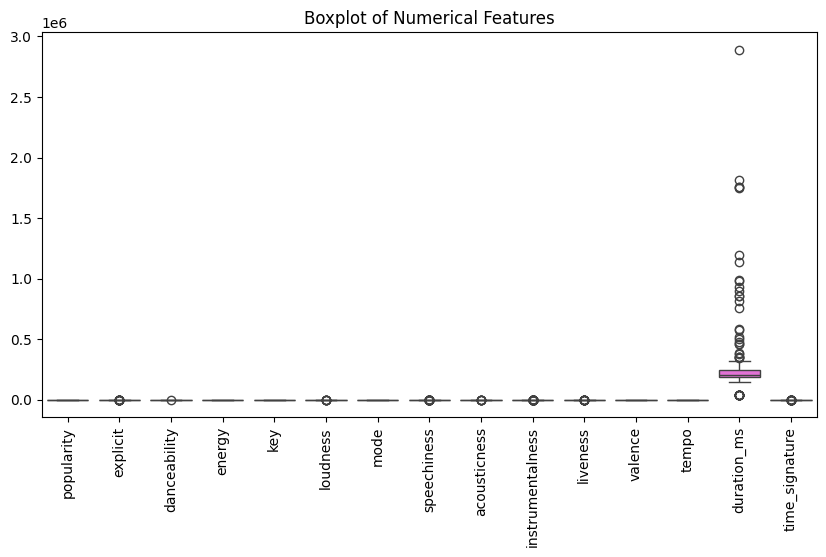

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df_final[num_cols])
plt.xticks(rotation=90)
plt.title("Boxplot of Numerical Features")
plt.show()

The boxplot reveals that duration_ms is on a much larger scale
compared to other numerical features.
Most audio features range between 0 and 1, while duration is in millions.
This scale imbalance can distort distance-based algorithms.
Therefore, feature standardization is necessary before clustering.
Additionally, extreme duration values indicate potential outliers.

## Popularity vs Audio Features

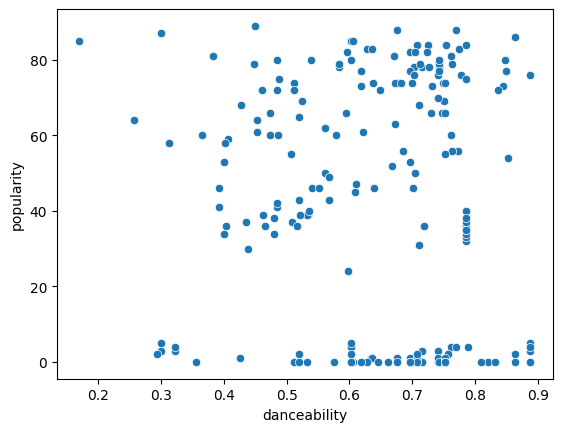

In [ ]:
sns.scatterplot(x="danceability", y="popularity", data=df_final)
plt.show()

Some songs with high danceability are very popular.

But some songs with high danceability are NOT popular.

Some songs with medium danceability are very popular.

Some songs with low danceability are also popular.

The dots are scattered everywhere.
There is no clear pattern like:
"More danceability = more popularity"

In [ ]:
# This computes the Pearson correlation between danceability and popularity
# to understand whether more danceable songs tend to be more popular.
df_final["danceability"].corr(df_final["popularity"])

np.float64(-0.1193824090155634)

The Pearson correlation coefficient between danceability and popularity is approximately −0.12, indicating a very weak negative relationship. This suggests that danceability alone does not significantly influence song popularity. Therefore, popularity is likely affected by multiple factors rather than a single acoustic feature.

In [ ]:
df_final[num_cols].corr()["popularity"].sort_values()
# This analysis shows the correlation between audio features and popularity.
# Most correlations are weak, indicating that popularity is not strongly
# determined by a single audio feature but likely depends on multiple factors.


,popularity
valence,-0.142862
mode,-0.139129
key,-0.126745
danceability,-0.119382
speechiness,-0.100772
acousticness,-0.026004
tempo,-0.006090
instrumentalness,0.000338
time_signature,0.021366
duration_ms,0.026518


In [ ]:
df_final.dtypes

,0
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
explicit,int64
track_genre,object
danceability,float64
energy,float64
key,float64


# Cluster

# K-Means

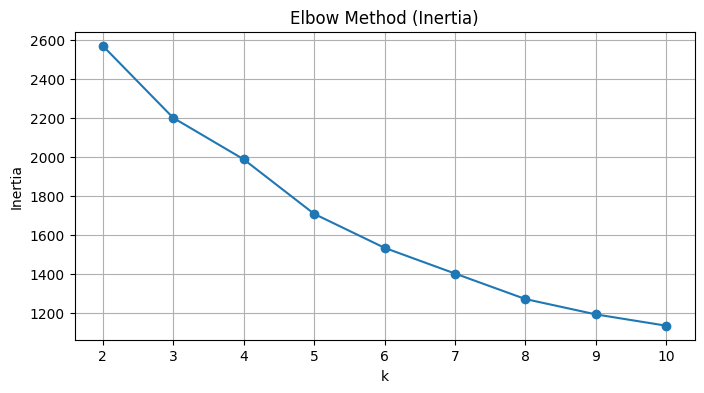

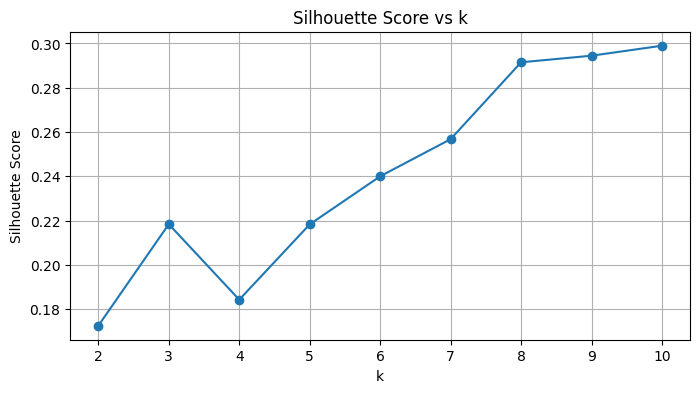

Best k = 10 Best silhouette = 0.29894870709818766


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Use only audio features (drop popularity and explicit)
X = df_final.select_dtypes(include=["number"]).drop(columns=["popularity", "explicit"])

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow + Silhouette
K_range = range(2, 11)
inertias = []
sil_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

# Plot Elbow
plt.figure(figsize=(8, 4))
plt.plot(list(K_range), inertias, marker="o")
plt.title("Elbow Method (Inertia)")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

# Plot Silhouette
plt.figure(figsize=(8, 4))
plt.plot(list(K_range), sil_scores, marker="o")
plt.title("Silhouette Score vs k")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

best_k = list(K_range)[int(np.argmax(sil_scores))]
print("Best k =", best_k, "Best silhouette =", max(sil_scores))

The Elbow method suggests that the decrease in inertia slows significantly after k = 4–5, indicating that additional clusters provide limited improvement. Although the Silhouette score reached its maximum at k = 10, a smaller number of clusters was selected to maintain meaningful cluster sizes and interpretability.The optimal number of clusters was determined using both the Elbow method and the Silhouette score. Although the Silhouette score increased with larger values of k, the Elbow method indicated that the improvement in inertia slows after k ≈ 4–5. Therefore, k = 5 was selected as a balanced choice providing meaningful cluster structure and interpretability.

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_final["cluster"] = kmeans.fit_predict(X_scaled)

/tmp/ipykernel_267/2957893268.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final["cluster"] = kmeans.fit_predict(X_scaled)


In [ ]:
df_final.groupby("cluster").mean(numeric_only=True)

,popularity,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
cluster,,,,,,,,,,,,,,,
0,31.053571,0.107143,0.748339,0.623768,8.357143,-8.479161,0.589286,0.102084,0.150518,0.011126,0.126941,0.691643,129.747661,2.161224e+05,4.000000
1,48.224719,0.146067,0.590337,0.734146,3.202247,-5.338360,0.629213,0.068934,0.118854,0.050891,0.191445,0.388349,126.765730,2.336746e+05,3.988764
2,34.520000,0.060000,0.655340,0.408900,4.360000,-11.264520,0.800000,0.155182,0.546754,0.182732,0.133040,0.385580,104.762700,2.169889e+05,3.840000
3,40.111111,0.000000,0.485778,0.687722,4.000000,-8.980667,0.777778,0.093767,0.540500,0.015786,0.560372,0.757167,124.204000,1.134002e+06,3.722222
4,36.866667,0.000000,0.786000,0.803000,6.000000,-7.170000,0.000000,0.483000,0.235000,0.000000,0.360000,0.675000,137.493000,3.850000e+04,1.000000


Cluster analysis using K-Means with k = 5 identified five groups of songs with different musical characteristics. Cluster 0 contains highly danceable and positive-mood songs with relatively high tempo. Cluster 1 represents energetic and loud tracks and shows the highest average popularity among all clusters. Cluster 2 is characterized by high acousticness and lower energy, indicating calmer and more acoustic songs. Clusters 3 and 4 capture special cases, including songs with high liveness and long duration (live or extended tracks) and very fast, energetic tracks with high tempo and danceability

In [ ]:
df_final["cluster"].value_counts() #This shows how many songs belong to each cluster.

,count
cluster,
1,89
0,56
2,50
3,18
4,15


The K-Means algorithm produced clusters of varying sizes, ranging from 15 to 89 observations. Although the clusters are not perfectly balanced, each cluster contains a sufficient number of songs to represent distinct musical patterns in the dataset.

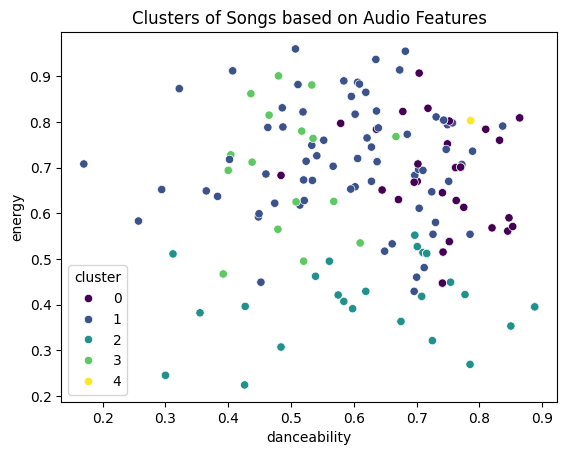

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
# A scatter plot of danceability vs energy is used to visualize the clusters.
# These features represent important musical characteristics and show strong
# variation across songs, making them useful for interpreting cluster structure.
# However, the clustering itself was performed using multiple audio features.

sns.scatterplot(
    data=df_final,
    x="danceability",
    y="energy",
    hue="cluster",
    palette="viridis"
)

plt.title("Clusters of Songs based on Audio Features")
plt.show()

The scatter plot visualization shows overlapping clusters because it only represents two features, namely danceability and energy, while the K-Means clustering algorithm was trained using many audio features simultaneously. Since the clustering was performed in a high-dimensional feature space, important differences between songs may exist in other dimensions that cannot be observed in a simple two-dimensional plot. As a result, clusters that are actually separated in higher-dimensional space may appear overlapped when projected onto only two variables. To better visualize the true structure of the data, dimensionality reduction techniques such as t-SNE or PCA are applied. These methods project the high-dimensional feature space into two dimensions while preserving as much of the original structure as possible, allowing clusters to become more distinguishable in visualization.

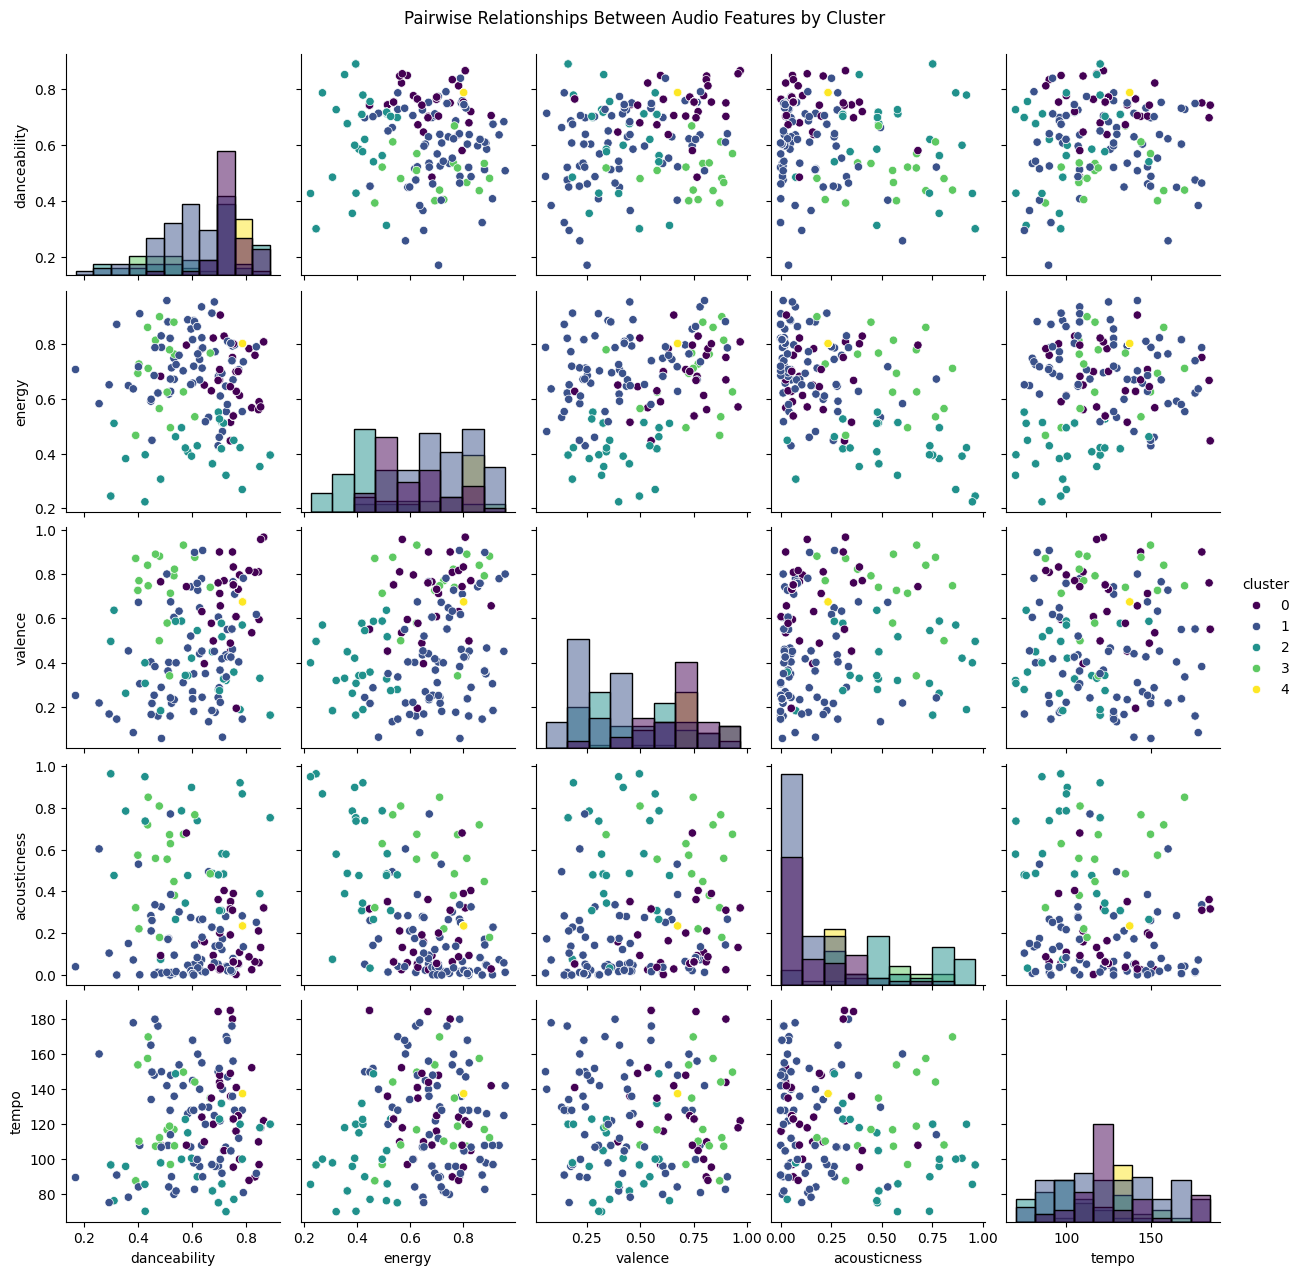

In [ ]:
# A pairplot visualization is used to explore relationships between several
# audio features and to observe how clusters are distributed across different
# musical characteristics.

# Select a few meaningful audio features
features = [
    "danceability",
    "energy",
    "valence",
    "acousticness",
    "tempo",
    "cluster"
]

sns.pairplot(
    df_final[features],
    hue="cluster",
    palette="viridis",
    diag_kind="hist"
)

plt.suptitle("Pairwise Relationships Between Audio Features by Cluster", y=1.02)
plt.show()

# DBSCAN

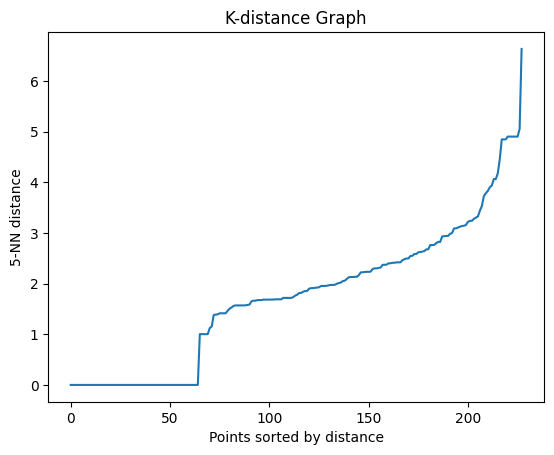

In [ ]:
# choosing eps value using K-distance Graph method

from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:,4], axis=0)

plt.plot(distances)
plt.xlabel("Points sorted by distance")
plt.ylabel("5-NN distance")
plt.title("K-distance Graph")
plt.show()

To choose the epsilon (ε) value for DBSCAN, a 5-nearest neighbor (5-NN) distance graph was used. In this graph, the distances are sorted and plotted to identify the “elbow point,” where the curve starts to increase more sharply. This point helps determine a suitable ε value that separates dense clusters from noise. From the plot, the curve begins to bend and gradually rise between 2 and 3.5, while after 3.5 it increases more steeply. Therefore, a reasonable range for ε is between 2 and 3.5, since values below 2 may produce too much noise and values above 3.5 may merge different clusters together.

So i choose the value in-between 2.5 for DBSCAN eps.


In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=2.5, min_samples=5)

df_final["dbscan_cluster"] = dbscan.fit_predict(X_scaled)
df_final["dbscan_cluster"].value_counts()

/tmp/ipykernel_267/579094706.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final["dbscan_cluster"] = dbscan.fit_predict(X_scaled)


,count
dbscan_cluster,
0,136
-1,45
4,18
3,15
2,7
1,7


In [ ]:
from sklearn.metrics import silhouette_score

silhouette = silhouette_score(X_scaled, df_final["dbscan_cluster"])
print("Silhouette Score:", silhouette)

Silhouette Score: 0.2022998078207547


The Silhouette Score was calculated to evaluate the quality of the DBSCAN clustering. The obtained score of 0.20 indicates moderate cluster separation with some overlap between groups. When compared with the K-Means clustering results(score was 0.29), DBSCAN produced slightly weaker cluster separation, suggesting that K-Means is more suitable for grouping songs based on audio features in this dataset.

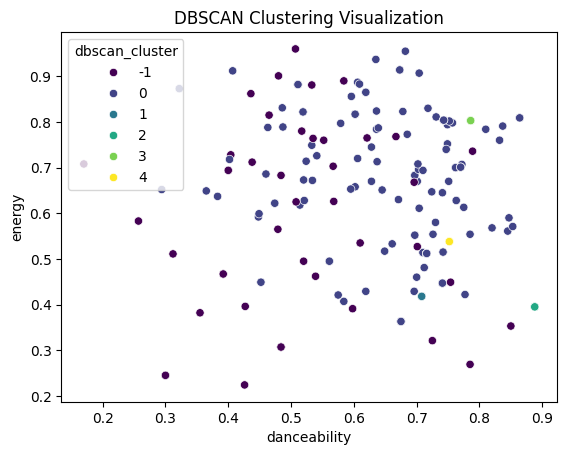

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df_final,
    x="danceability",
    y="energy",
    hue="dbscan_cluster",
    palette="viridis"
)

plt.title("DBSCAN Clustering Visualization")
plt.show()

In [ ]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 228 entries, 0 to 547
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          228 non-null    object 
 1   artists           228 non-null    object 
 2   album_name        228 non-null    object 
 3   track_name        228 non-null    object 
 4   popularity        228 non-null    int64  
 5   explicit          228 non-null    int64  
 6   track_genre       228 non-null    object 
 7   danceability      228 non-null    float64
 8   energy            228 non-null    float64
 9   key               228 non-null    float64
 10  loudness          228 non-null    float64
 11  mode              228 non-null    float64
 12  speechiness       228 non-null    float64
 13  acousticness      228 non-null    float64
 14  instrumentalness  228 non-null    float64
 15  liveness          228 non-null    float64
 16  valence           228 non-null    float64
 17  te

# Dimension Reduction

# ISOMAP

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 3 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
/usr/local/lib/python3.12/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
/usr/local/lib/python3.12/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
/usr/local/lib/python3.12/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


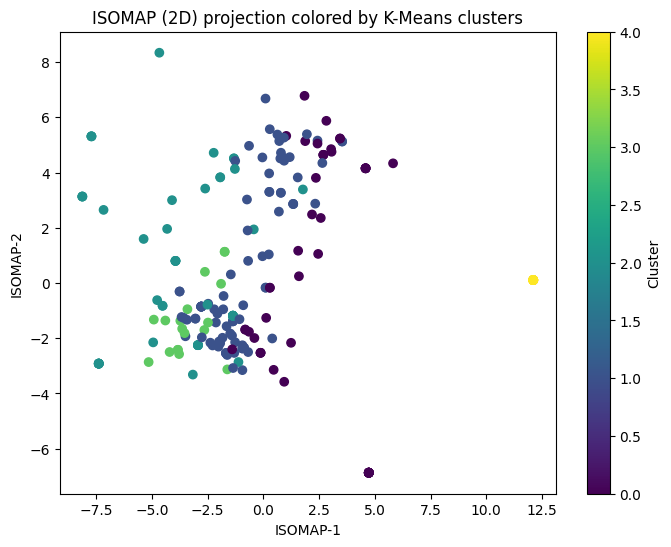

In [ ]:
from sklearn.manifold import Isomap


# Use numeric audio features only (exclude popularity/explicit for clustering space)
X = df_final.select_dtypes(include=["number"]).drop(
    columns=["cluster", "popularity", "explicit"], errors="ignore"
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

isomap = Isomap(n_neighbors=8, n_components=2)
X_iso = isomap.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
plt.scatter(X_iso[:,0], X_iso[:,1], c=df_final["cluster"], cmap="viridis")
plt.title("ISOMAP (2D) projection colored by K-Means clusters")
plt.xlabel("ISOMAP-1")
plt.ylabel("ISOMAP-2")
plt.colorbar(label="Cluster")
plt.show()

Different values of the n_neighbors parameter were tested in the ISOMAP algorithm to evaluate how neighborhood size affects the manifold representation. Smaller values such as n_neighbors = 5 focus on very local relationships and produced a noisier projection, while larger values such as n_neighbors = 10 overly smooth the structure of the data. The value n_neighbors = 8 provided the most balanced representation, preserving both local relationships between similar songs and the overall structure of the dataset. Therefore, n_neighbors = 8 was selected for the final ISOMAP visualization

Important Note

Even with the best parameter, some overlap remains, which is normal because:

-musical features vary continuously

-song categories are not strictly separated

This is why dimensionality reduction is mainly used for visual exploration rather than perfect cluster separation.

In [ ]:
# evaluation of original features

from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

labels = df_final["cluster"].values

sil = silhouette_score(X_scaled, labels)
dbi = davies_bouldin_score(X_scaled, labels)
chi = calinski_harabasz_score(X_scaled, labels)

print("Evaluation on original scaled features:")
print("Silhouette Score (higher better):", sil)
print("Davies-Bouldin Index (lower better):", dbi)
print("Calinski-Harabasz Index (higher better):", chi)

Evaluation on original scaled features:
Silhouette Score (higher better): 0.22324125589642788
Davies-Bouldin Index (lower better): 1.5363818301484726
Calinski-Harabasz Index (higher better): 41.18749573446131


Clustering quality was evaluated using several internal validation metrics. The Silhouette Score of 0.223 indicates moderate separation between clusters with some overlap. The Davies–Bouldin Index of 1.53 suggests that clusters are reasonably compact(how cluster are compact) and separated(distance between cluster centers), while the Calinski–Harabasz(which measure between-cluster variance
vs within-cluster variance) Index of 41.18 indicates a moderate level of cluster structure in the dataset. These results suggest that the K-Means algorithm captures meaningful groupings in the audio feature space, although the clusters are not perfectly distinct due to the continuous nature of musical characteristics.

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sil_isomap = silhouette_score(X_iso, df_final["cluster"])
dbi_isomap = davies_bouldin_score(X_iso, df_final["cluster"])
chi_isomap = calinski_harabasz_score(X_iso, df_final["cluster"])

print("Evaluation on ISOMAP features:")
print("Silhouette Score:", sil_isomap)
print("Davies-Bouldin Index:", dbi_isomap)
print("Calinski-Harabasz Index:", chi_isomap)

Evaluation on ISOMAP features:
Silhouette Score: -0.007894309714020057
Davies-Bouldin Index: 1.8971351893303001
Calinski-Harabasz Index: 63.61719737796029


The clustering evaluation was also performed in the ISOMAP-reduced feature space. The Silhouette Score decreased to −0.008, indicating that cluster separation is not well preserved in the two-dimensional projection. The Davies–Bouldin Index increased compared to the original feature space, suggesting reduced cluster compactness after dimensionality reduction. However, the Calinski–Harabasz Index increased slightly, indicating that some global structure remains visible. These results highlight that dimensionality reduction techniques such as ISOMAP are primarily useful for visualization rather than for evaluating clustering performance.

# t-SNE


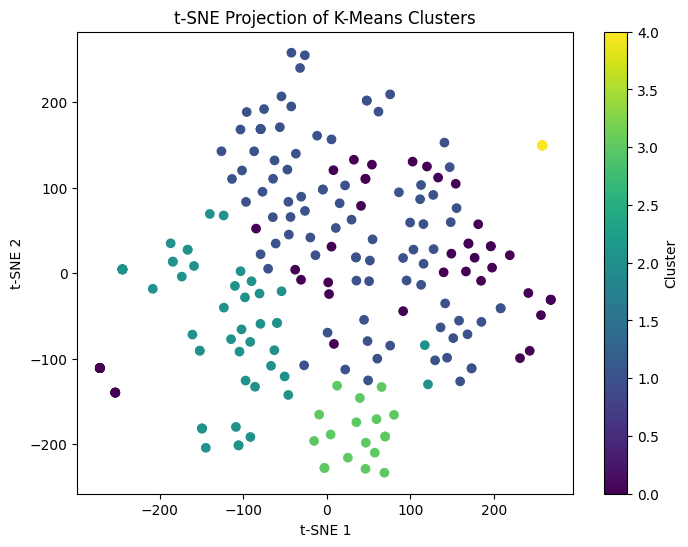

In [ ]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import matplotlib.pyplot as plt

# t-SNE dimensionality reduction
tsne = TSNE(
    n_components=2,
    perplexity=25,     # good value for ~200 samples
    learning_rate='auto',
    init='pca',
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

# Plot clusters in t-SNE space
plt.figure(figsize=(8,6))
plt.scatter(X_tsne[:,0], X_tsne[:,1], c=df_final["cluster"], cmap="viridis")
plt.title("t-SNE Projection of K-Means Clusters")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.colorbar(label="Cluster")
plt.show()

In [ ]:
# evalution
sil_tsne = silhouette_score(X_tsne, df_final["cluster"])
dbi_tsne = davies_bouldin_score(X_tsne, df_final["cluster"])
chi_tsne = calinski_harabasz_score(X_tsne, df_final["cluster"])

print("Evaluation on t-SNE features:")
print("Silhouette Score:", sil_tsne)
print("Davies-Bouldin Index:", dbi_tsne)
print("Calinski-Harabasz Index:", chi_tsne)

Evaluation on t-SNE features:
Silhouette Score: 0.12729292
Davies-Bouldin Index: 2.4042243296426635
Calinski-Harabasz Index: 38.348797


The clustering structure was also evaluated in the t-SNE reduced feature space. The obtained Silhouette Score of 0.127 indicates weak to moderate separation between clusters, suggesting that some overlap exists among groups in the two-dimensional embedding. The Davies–Bouldin Index of 2.40 reflects lower cluster compactness compared to the original feature space, meaning that clusters appear less well separated after the dimensionality reduction. The Calinski–Harabasz Index of 38.35 still indicates that some cluster structure is preserved in the projection. Overall, these results show that while t-SNE can reveal local patterns and provide useful visualization of the data distribution, it may reduce the clarity of cluster separation due to the compression of high-dimensional information into two dimensions.

# PCA

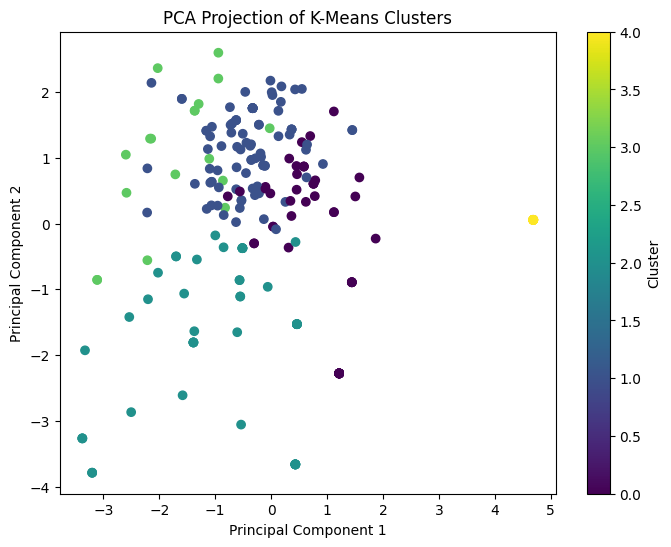

Explained variance ratio: [0.1982596  0.16913535]
Total explained variance: 0.36739494831700364


In [ ]:
from sklearn.decomposition import PCA

# Apply PCA to reduce to 2 dimensions
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Plot PCA projection
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=df_final["cluster"], cmap="viridis")
plt.title("PCA Projection of K-Means Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

# Explained variance
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

PCA was applied to reduce the dimensionality of the standardized audio features to two principal components for visualization purposes. The first two components explain approximately 36.7% of the total variance, indicating that a portion of the information is preserved while reducing the dimensionality of the dataset. The resulting projection shows partially separated clusters, suggesting that the K-Means algorithm captures meaningful structure in the data, although some overlap remains due to similarities in musical characteristics between songs.

In [ ]:
# evaluation of PCA

labels = df_final["cluster"].values

sil_pca = silhouette_score(X_pca, labels)
dbi_pca = davies_bouldin_score(X_pca, labels)
chi_pca = calinski_harabasz_score(X_pca, labels)

print("Evaluation on PCA features:")
print("Silhouette Score:", sil_pca)
print("Davies-Bouldin Index:", dbi_pca)
print("Calinski-Harabasz Index:", chi_pca)

Evaluation on PCA features:
Silhouette Score: 0.23616304280181108
Davies-Bouldin Index: 1.2165912120355602
Calinski-Harabasz Index: 119.7614918418275


Clustering performance was also evaluated in the PCA-reduced feature space. The results show an improvement compared to the original feature space, with a Silhouette Score of 0.236 and a lower Davies–Bouldin Index of 1.21, indicating better cluster compactness and separation. Additionally, the Calinski–Harabasz Index increased significantly to 119.76, suggesting a stronger cluster structure after dimensionality reduction. These results indicate that PCA effectively reduces noise and preserves meaningful variance in the dataset, improving the representation of clusters.

# Comparisons of different dimension reduction method

In [ ]:


comparison = pd.DataFrame({
    "Feature Space": ["Original", "PCA", "ISOMAP", "t-SNE"],
    "Silhouette Score": [0.22324125589642788, 0.23616304280181108, -0.007894309714020057, 0.12729292],
    "Davies-Bouldin Index": [1.5363818301484726, 1.2165912120355602, 1.8971351893303001, 2.4042243296426635],
    "Calinski-Harabasz Index": [41.18749573446131, 119.7614918418275, 63.61719737796029, 38.348797]
})

comparison

,Feature Space,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Original,0.223241,1.536382,41.187496
1,PCA,0.236163,1.216591,119.761492
2,ISOMAP,-0.007894,1.897135,63.617197
3,t-SNE,0.127293,2.404224,38.348797


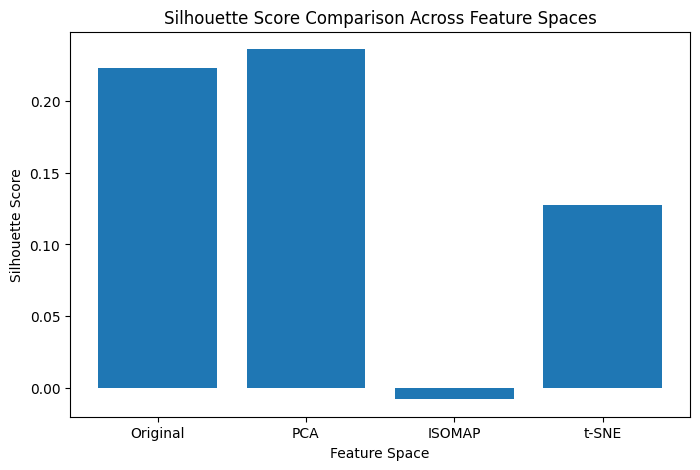

In [ ]:

plt.figure(figsize=(8,5))
plt.bar(comparison["Feature Space"], comparison["Silhouette Score"])
plt.title("Silhouette Score Comparison Across Feature Spaces")
plt.ylabel("Silhouette Score")
plt.xlabel("Feature Space")
plt.show()

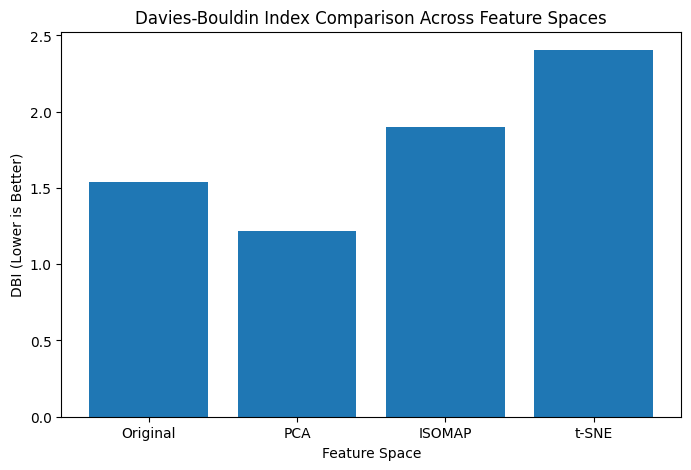

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(comparison["Feature Space"], comparison["Davies-Bouldin Index"])
plt.title("Davies-Bouldin Index Comparison Across Feature Spaces")
plt.ylabel("DBI (Lower is Better)")
plt.xlabel("Feature Space")
plt.show()

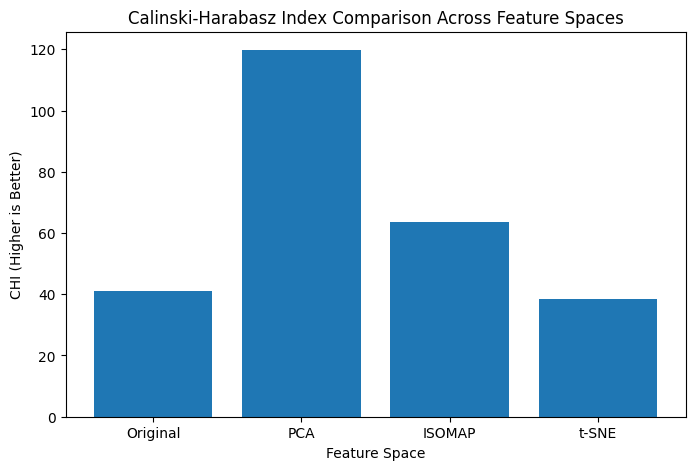

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(comparison["Feature Space"], comparison["Calinski-Harabasz Index"])
plt.title("Calinski-Harabasz Index Comparison Across Feature Spaces")
plt.ylabel("CHI (Higher is Better)")
plt.xlabel("Feature Space")
plt.show()

A comparison of clustering evaluation metrics across different feature spaces shows that PCA provides the best representation of cluster structure. PCA achieved the highest Silhouette Score (0.236), the lowest Davies–Bouldin Index (1.216), and the highest Calinski–Harabasz Index (119.76), indicating improved cluster compactness and separation. In contrast, ISOMAP and t-SNE reduced cluster separability due to information compression during dimensionality reduction. Therefore, PCA appears to be the most suitable dimensionality reduction technique for preserving clustering structure in this dataset.

### conclusion

This project explored the structure of Spotify songs by combining metadata and audio features from multiple datasets. Through exploratory data analysis and K-Means clustering, several groups of songs with similar musical characteristics were identified. The evaluation metrics confirmed that the clusters represent meaningful patterns within the dataset, although some overlap exists due to the continuous nature of audio features. Dimensionality reduction techniques were applied to visualize the data structure, and the comparison showed that PCA preserves cluster structure better than ISOMAP and t-SNE. Overall, the project demonstrates how unsupervised learning can reveal hidden relationships and patterns in large music datasets.

# Key Findings

1. The analysis revealed that songs can be grouped into distinct clusters based on their audio characteristics such as danceability, energy, loudness, acousticness, and tempo.

2. K-Means clustering successfully identified five meaningful musical profiles, demonstrating that songs with similar acoustic properties naturally form groups.

3. The clusters represent different types of musical styles, including energetic tracks, acoustic songs, and balanced mainstream music.

4. Popularity showed weak correlation with most audio features, suggesting that commercial success depends on external factors such as artist reputation, marketing, and listener trends.

5. Dimensionality reduction techniques were applied to visualize the high-dimensional feature space, and PCA preserved the cluster structure more effectively than ISOMAP and t-SNE.

6. DBSCAN clustering indicated that the dataset contains one large dense region and several smaller clusters, confirming that music features are continuously distributed rather than strongly separated.

# Future work

1. Future work could explore additional clustering algorithms such as hierarchical clustering or Gaussian mixture models to compare cluster structures.

2. Incorporating larger and more diverse music datasets could improve the robustness of the analysis and provide deeper insights into global music patterns.

3. Additional features such as lyrical content, artist popularity, or playlist data could be integrated to better understand factors influencing song popularity.

4. Recommendation systems could be developed using the discovered clusters to suggest similar songs based on acoustic characteristics.

5. Advanced deep learning techniques such as autoencoders could be used to learn more complex representations of musical features.